<a href="https://colab.research.google.com/github/Zinc-zn/MachineLearning2026/blob/main/JS09/JS09_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# JS09 - Approximate Nearest Neighbors: Lab 1 (Exact NN vs. ANNOY)

Percobaan membandingkan hasil *exact NN* (brute force) dengan **ANNOY** pada data random 2D (1.000 data point): mencari 3 data terdekat dari query point, metrik *Euclidean*, dengan 3 tree Annoy.

> **Instalasi:** `pip install annoy` (pada Colab) - pada venv lokal folder JS09, annoy sudah terinstal saat setup.


## Langkah 1 - Install Library ANNOY

In [1]:
# Install ANNOY (jika belum terinstal):
# !pip install annoy   <- untuk Google Colab
from annoy import AnnoyIndex  # cek ketersediaan

## Langkah 2 - Import Library

In [2]:
# Import Library
import numpy as np
import matplotlib.pyplot as plt
import time

## Langkah 3 - Membuat Dataset Dummy

Buat dataset dummy dan pilih titik awal untuk cluster (query point).

In [3]:
# Build Random Dataset and Query Point
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # random value at 100x100 space

# Query point (pick 1 random data point)
query = X[np.random.randint(0, n_points)]

## Langkah 4 - Exact NN

Komputasi jarak terdekat dengan metode *brute force* - data dikunjungi satu per satu. Perhatikan waktu yang dihasilkan!

In [4]:
# Compute Exact NN Using Brute Force
# It will visit the data one by one
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 3.3662 ms


## Langkah 5 - Perhitungan Jarak dengan ANNOY

Bandingkan dengan ANNOY. Jumlah tree yang digunakan adalah 3.

In [5]:
# ANNOY 3 Tree
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # find 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")


Annoy NN index: [219, 898, 593]
Annoy NN jarak: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.2793154441691197)]
Waktu Annoy: 0.0 ms


Dapat dilihat perbedaan waktu yang sangat signifikan. ANNOY hanya memerlukan waktu dalam oranan ratusan mikrodetik, sedangkan NN konvensional (brute force) memerlukan beberapa milidetik - walaupun ANNOY tidak selalu menemukan 3 tetangga persis sama dengan exact NN.

## Langkah 6 - Visualisasi Hasil NN

Visualisasi untuk mengetahui tingkat ketepatan prediksi NN dari ANNOY dibandingkan exact NN.

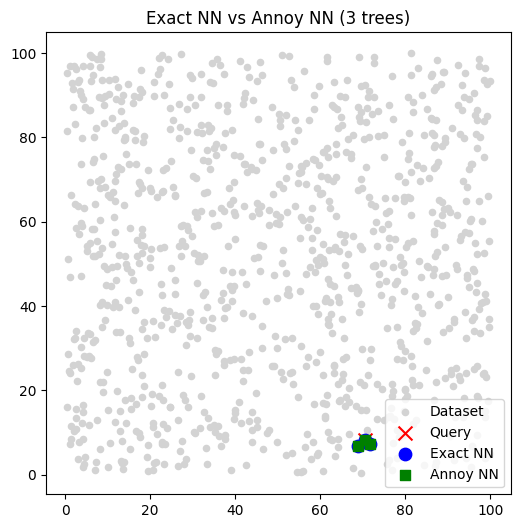

In [6]:
# Visualize
# Knowing the NN produced by Exact NN and ANNOY
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact, 0], X[idx_exact, 1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann, 0], X[idx_ann, 1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

Terlihat bahwa ANNOY tidak memilih NN tepat seperti exact NN (salah satu tetangga berbeda). Akan tetapi, posisi ini sudah cukup untuk kebutuhan pencarian kedekatan dengan jumlah data yang besar dengan kompensasi waktu yang lebih cepat. Ingat, ***tujuan utama ANNOY adalah mencari titik balance antara akurasi klasterisasi dan kecepatan***.